# QEcon validation

How we know the circuit computes what we say it computes. This notebook holds all of the
validation code: the independent reference, the classical baseline, 33 checks and the five
figures. Run it top to bottom with **Run All**. It takes about a minute.

**What it depends on.** Snigdha's `core/engine.py` is imported rather than copied, because it
is the thing being tested. Use the kernel from the repo's `.venv`.

**Sign and spin convention.** $H = -\sum J_{ij} Z_i Z_j - \sum h_i Z_i - \sum \Gamma_i X_i$,
with $|0\rangle$ meaning $Z=+1$ (solvent, comply, hold) and $|1\rangle$ meaning $Z=-1$
(failed, evade, raise).

Figures and their numbers are saved to `validation/figures/`. The reasoning behind each choice
is in `PLAN.md`.

## Setup

In [1]:
import json
import math
import sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from qiskit.quantum_info import Statevector, entropy, partial_trace
from scipy.sparse.linalg import expm_multiply

# Find the repo root so this runs whether Jupyter starts in the root or in validation/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core" / "engine.py").exists())
sys.path.insert(0, str(ROOT))

# Snigdha's engine is what we are testing, so it is imported, not copied.
from core.engine import compile_ising, evolve, exact_state

print("Repo root:", ROOT)

Repo root: C:\Users\Shiven\Desktop\hackathons\Qiskit-Fall-QuantumLarpers


## The standard test system

Every check and figure uses this system.

- **2D grid:** a 1D nearest-neighbour chain is classically solvable.
- **h ≠ 0:** breaks the free-fermion solution.
- **Different J, h, Γ on every site:** uniform values hide qubit-order bugs.

In [2]:
SEED = 7
ROWS, COLS = 3, 4
INIT_ONES = (0, 5)   # agents that start in |1> (failed / evading / raising)
T_REF = 1.0          # evolution time used for the convergence figures
STEPS = (1, 2, 4, 8, 16, 32)
FIT_FROM = 4         # slopes fit r >= 4 only; r = 1, 2 are outside the small-step regime


@dataclass(frozen=True)
class System:
    n: int
    edges: dict
    h: np.ndarray
    gamma: np.ndarray
    init_ones: tuple


def grid_edges(rows, cols):
    """Nearest-neighbour edges of a rows x cols grid, as (i, j) index pairs."""
    pairs = []
    for a in range(rows):
        for b in range(cols):
            q = a * cols + b
            if b + 1 < cols:
                pairs.append((q, q + 1))
            if a + 1 < rows:
                pairs.append((q, q + cols))
    return pairs


def standard_system(gamma_scale=1.0, seed=SEED, rows=ROWS, cols=COLS, init_ones=INIT_ONES):
    """3x4 heterogeneous grid. gamma_scale=0 gives the same system with Gamma off."""
    rng = np.random.default_rng(seed)
    n = rows * cols
    edges = {pair: float(rng.uniform(0.5, 1.5)) for pair in grid_edges(rows, cols)}
    h = rng.uniform(-0.6, 0.6, n)
    gamma = rng.uniform(0.3, 0.7, n) * gamma_scale
    return System(n, edges, h, gamma, tuple(init_ones))

## Independent reference

`core.engine.exact_state` builds its matrix from the same `SparsePauliOp` the circuit uses, so
a bug in `compile_ising` would appear on both sides and cancel. Everything here starts from the
raw `(edges, h, gamma)` and uses only NumPy and SciPy.

Convention: bit `i` of a basis index is qubit `i`.

In [3]:
def spins(n):
    """Array of shape (n, 2^n): the Z eigenvalue of qubit i in each basis state."""
    idx = np.arange(1 << n)
    return np.array([1 - 2 * ((idx >> i) & 1) for i in range(n)])


def diagonal_energy(n, edges, h):
    """-sum J s_i s_j - sum h s_i for every basis state."""
    s = spins(n)
    energy = np.zeros(1 << n)
    for (i, j), J in edges.items():
        energy -= J * s[i] * s[j]
    for i in range(n):
        energy -= h[i] * s[i]
    return energy


def hamiltonian(n, edges, h, gamma):
    """H = -sum J Z_i Z_j - sum h Z_i - sum Gamma X_i as a sparse matrix."""
    dim = 1 << n
    idx = np.arange(dim)
    H = sp.diags(diagonal_energy(n, edges, h)).tocsr().astype(complex)
    for i in range(n):
        if gamma[i]:
            flip = sp.csr_matrix(
                (np.full(dim, -gamma[i], dtype=complex), (idx ^ (1 << i), idx)),
                shape=(dim, dim),
            )
            H = H + flip
    return H.tocsc()


def basis_state(n, init_ones=()):
    psi = np.zeros(1 << n, dtype=complex)
    psi[sum(1 << q for q in init_ones)] = 1.0
    return psi


def exact_evolve(system, t):
    """exp(-itH)|init>, built without Qiskit."""
    H = hamiltonian(system.n, system.edges, system.h, system.gamma)
    return expm_multiply(-1j * t * H, basis_state(system.n, system.init_ones))


def exact_series(system, times):
    """Exact states at each time. Rows follow `times`."""
    H = hamiltonian(system.n, system.edges, system.h, system.gamma)
    psi0 = basis_state(system.n, system.init_ones)
    return np.array([expm_multiply(-1j * t * H, psi0) for t in times])


def infidelity(a, b):
    """1 - |<a|b>|^2. Rounding can make this about -1e-15, so don't take its log raw."""
    return 1.0 - abs(np.vdot(a, b)) ** 2


def z_expectations(psi, n):
    """<Z_i> for every qubit, from the probabilities."""
    return spins(n) @ (np.abs(psi) ** 2)


def magnetization(psi, n):
    return float(z_expectations(psi, n).mean())


def zz_expectation(psi, n, i, j):
    s = spins(n)
    return float((s[i] * s[j]) @ (np.abs(psi) ** 2))


def x_bar(psi, n):
    """Average <X_i>. Off-diagonal, so it sees phases that Z-basis numbers cannot."""
    idx = np.arange(1 << n)
    return float(np.mean([np.real(np.vdot(psi, psi[idx ^ (1 << i)])) for i in range(n)]))


def half_entropy(psi, n, k=None):
    """Entanglement entropy in bits between qubits 0..k-1 and the rest.

    Basis index = high_bits * 2^k + low_bits, so reshaping to (2^(n-k), 2^k) puts the
    kept qubits on the columns. Schmidt weights are the squared singular values.
    """
    k = n // 2 if k is None else k
    weights = np.linalg.svd(psi.reshape(1 << (n - k), 1 << k), compute_uv=False) ** 2
    weights = weights[weights > 1e-14]
    return max(0.0, float(-(weights * np.log2(weights)).sum()))


def slope(steps, values, fit_from):
    """Log-log slope using only points with steps >= fit_from."""
    r = np.array(steps, dtype=float)
    y = np.array(values, dtype=float)
    keep = r >= fit_from
    return float(np.polyfit(np.log(r[keep]), np.log(y[keep]), 1)[0])

## Classical baseline: Glauber Monte Carlo

The kind of model the econophysics papers run, such as Zaklan's taxpayers: one definite
bit-string per replica, with spins flipped at random. It uses the Γ = 0 energy function.

In [4]:
def coupling_matrix(n, edges):
    J = np.zeros((n, n))
    for (i, j), value in edges.items():
        J[i, j] = J[j, i] = value
    return J


def glauber_energy(s, J, h):
    """-sum_{i<j} J s_i s_j - sum h s_i for rows of spins s."""
    return -0.5 * np.einsum("ri,ij,rj->r", s, J, s) - s @ h


def glauber_flip_cost(s, sites, J, h):
    """Energy change from flipping one spin per replica. `sites` is an int or one per row."""
    rows = np.arange(len(s))
    sites = np.broadcast_to(sites, rows.shape)
    return 2.0 * s[rows, sites] * (np.einsum("ri,ri->r", s, J[sites]) + h[sites])


def run_glauber(system, temperature, sweeps, replicas=4000, seed=0):
    """Returns per-agent <s_i> after each sweep, shape (sweeps + 1, n).

    One sweep is n single-spin update attempts per replica. Each replica picks its own
    site: sharing one site across replicas makes the whole ensemble jump in lockstep.
    """
    rng = np.random.default_rng(seed)
    n = system.n
    J = coupling_matrix(n, system.edges)
    s = np.ones((replicas, n))
    s[:, list(system.init_ones)] = -1.0
    rows = np.arange(replicas)
    history = [s.mean(axis=0)]
    for _ in range(sweeps):
        for _ in range(n):
            sites = rng.integers(n, size=replicas)
            accept = 1.0 / (1.0 + np.exp(glauber_flip_cost(s, sites, J, system.h) / temperature))
            flipped = rng.random(replicas) < accept
            s[rows[flipped], sites[flipped]] *= -1.0
        history.append(s.mean(axis=0))
    return np.array(history)

## Chart style and output

In [5]:

OUT = ROOT / "validation" / "figures"

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#8a8983"
GRID = "#e6e5e0"

# Fixed order, checked with the palette validator. Colour follows the entity.
BLUE = "#2a78d6"     # first order / coherent / Gamma > 0
ORANGE = "#eb6834"   # second order
AQUA = "#1baf7a"     # Gamma = 0 / classical reference

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.size": 13,
    "font.family": "sans-serif",
    "text.color": INK,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": INK_MUTED,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
    "legend.frameon": False,
    "legend.fontsize": 12,
})


def heading(fig, title, subtitle=None):
    """Claim-style title in the top-left, with an optional line of conditions under it."""
    fig.text(0.015, 0.975, title, fontsize=18, fontweight="bold", color=INK, va="top")
    if subtitle:
        fig.text(0.015, 0.905, subtitle, fontsize=12.5, color=INK_SECONDARY, va="top")


def save(fig, name, data):
    """Writes figures/<name>.png and figures/<name>.json. Slides quote the JSON."""
    OUT.mkdir(exist_ok=True)
    fig.savefig(OUT / f"{name}.png", dpi=200)
    plt.show()
    (OUT / f"{name}.json").write_text(json.dumps(data, indent=2) + "\n", encoding="utf-8")
    print(f"wrote {OUT / name}.png")

## The gate: 33 checks

No figure counts until these pass, and this cell stops the notebook if one fails. Each check is
a judge question answered in advance. The same logic lives in `test_engine.py` for pytest.

In [6]:
TIGHT = 1e-12
system = standard_system()
classical = standard_system(gamma_scale=0.0)


def compile_system(s):
    return compile_ising(s.n, s.edges, s.h, s.gamma)


def trotter_state(s, t, steps, order):
    return Statevector(evolve(compile_system(s), t, steps, s.init_ones, order)).data


def engine_hamiltonian_matches_independent_build():
    engine_H = compile_system(system).to_matrix(sparse=True).tocsc()
    independent_H = hamiltonian(system.n, system.edges, system.h, system.gamma)
    assert abs(engine_H - independent_H).max() < TIGHT


def engine_exact_state_matches_independent_evolution():
    engine = exact_state(compile_system(system), T_REF, system.init_ones)
    assert abs(infidelity(engine, exact_evolve(system, T_REF))) < TIGHT


def seeded_agents_land_on_the_right_qubits():
    psi = trotter_state(system, 0.0, 1, 2)
    expected = np.ones(system.n)
    expected[list(system.init_ones)] = -1.0
    assert np.allclose(z_expectations(psi, system.n), expected, atol=TIGHT)


def single_qubit_matches_analytic_rotation(t):
    """Catches the classic factor of 2: <Z>(t) = cos(2 Gamma t)."""
    gamma = 0.7
    psi = Statevector(evolve(compile_ising(1, {}, [0.0], [gamma]), t, 1)).data
    assert abs(abs(psi[0]) ** 2 - abs(psi[1]) ** 2 - np.cos(2 * gamma * t)) < TIGHT


def gamma_zero_has_no_motion_and_no_error(steps, order):
    """The most important test: with the transverse field off, nothing happens."""
    t = 2.3
    psi = trotter_state(classical, t, steps, order)
    start = basis_state(classical.n, classical.init_ones)
    assert np.abs(np.abs(psi) ** 2 - np.abs(start) ** 2).max() < TIGHT
    assert abs(infidelity(psi, exact_evolve(classical, t))) < TIGHT


def circuit_really_trotterizes():
    """Guards the trap: un-unrolled circuits silently evolve exactly."""
    exact = exact_evolve(system, T_REF)
    for order in (1, 2):
        assert infidelity(trotter_state(system, T_REF, 1, order), exact) > 1e-3


def infidelity_converges_at_theoretical_rate(order, expected, tolerance):
    exact = exact_evolve(system, T_REF)
    values = [infidelity(trotter_state(system, T_REF, r, order), exact) for r in STEPS]
    assert abs(slope(STEPS, values, FIT_FROM) - expected) < tolerance


def orders_agree_on_every_z_basis_probability(steps):
    """Order 1 and 2 differ by diagonal phases only. Needs all Z terms before X terms."""
    first = trotter_state(system, T_REF, steps, 1)
    second = trotter_state(system, T_REF, steps, 2)
    assert np.abs(np.abs(first) ** 2 - np.abs(second) ** 2).max() < TIGHT


def entropy_two_independent_routes_agree():
    state = Statevector(trotter_state(system, T_REF, 12, 2))
    n = system.n
    via_qiskit = entropy(partial_trace(state, list(range(n // 2, n))), base=2)
    assert abs(half_entropy(state.data, n) - via_qiskit) < 1e-9


def gamma_zero_entropy_stays_zero():
    for t in (0.5, 2.0, 4.0):
        psi = trotter_state(classical, t, 16, 2)
        assert half_entropy(psi, classical.n) < 1e-9


def glauber_energy_matches_hamiltonian_diagonal():
    """The classical baseline must use the same signs as the quantum model."""
    n = classical.n
    J = coupling_matrix(n, classical.edges)
    diagonal = diagonal_energy(n, classical.edges, classical.h)
    assert np.allclose(glauber_energy(spins(n).T.astype(float), J, classical.h), diagonal)


def glauber_reaches_the_exact_boltzmann_average():
    """Long-run Glauber must match the thermal average summed over all 4096 states."""
    temperature = 2.5
    n = classical.n
    energies = diagonal_energy(n, classical.edges, classical.h)
    weights = np.exp(-(energies - energies.min()) / temperature)
    exact = spins(n) @ (weights / weights.sum())
    history = run_glauber(classical, temperature, sweeps=300)
    assert np.abs(history[-100:].mean(axis=0) - exact).max() < 0.02


def glauber_replicas_update_independently():
    """Shared site choices would leave a seeded agent untouched in every replica at once."""
    history = run_glauber(classical, 2.5, sweeps=1)
    assert -1.0 < history[1][classical.init_ones[0]] < 1.0
    # A replica visits a given agent in a sweep with probability 1 - (1 - 1/n)^n, and a
    # visit moves that agent's spin by at most 2, which bounds the ensemble mean's jump.
    n = classical.n
    largest_possible_jump = 2 * (1 - (1 - 1 / n) ** n)
    per_sweep_jump = np.abs(np.diff(run_glauber(classical, 1.0, sweeps=10), axis=0)).max()
    assert per_sweep_jump < largest_possible_jump + 0.05


def glauber_flip_cost_matches_energy_difference():
    n = classical.n
    J = coupling_matrix(n, classical.edges)
    rng = np.random.default_rng(0)
    s = rng.choice([-1.0, 1.0], size=(50, n))
    for i in range(n):
        flipped = s.copy()
        flipped[:, i] *= -1.0
        difference = glauber_energy(flipped, J, classical.h) - glauber_energy(s, J, classical.h)
        assert np.allclose(glauber_flip_cost(s, i, J, classical.h), difference)


checks = [
    (engine_hamiltonian_matches_independent_build, ()),
    (engine_exact_state_matches_independent_evolution, ()),
    (seeded_agents_land_on_the_right_qubits, ()),
    *[(single_qubit_matches_analytic_rotation, (t,)) for t in (0.3, 1.1, 2.7)],
    *[(gamma_zero_has_no_motion_and_no_error, (r, o)) for o in (1, 2) for r in STEPS],
    (circuit_really_trotterizes, ()),
    (infidelity_converges_at_theoretical_rate, (1, -2.0, 0.2)),
    (infidelity_converges_at_theoretical_rate, (2, -4.0, 0.3)),
    *[(orders_agree_on_every_z_basis_probability, (r,)) for r in STEPS],
    (entropy_two_independent_routes_agree, ()),
    (gamma_zero_entropy_stays_zero, ()),
    (glauber_energy_matches_hamiltonian_diagonal, ()),
    (glauber_reaches_the_exact_boltzmann_average, ()),
    (glauber_replicas_update_independently, ()),
    (glauber_flip_cost_matches_energy_difference, ()),
]

failed = []
for check, args in checks:
    try:
        check(*args)
    except AssertionError as error:
        failed.append(f"{check.__name__}{args}: {error}")

print(f"{len(checks) - len(failed)} of {len(checks)} checks passed")
for line in failed:
    print("FAILED", line)
assert not failed, "Stop here: the figures below can't be trusted until these pass."

33 of 33 checks passed


## Fig 1: Trotter convergence and the Γ = 0 test

Never cut this one. Each point compares a real gate-level circuit against the independent
reference. Slopes use r ≥ 4 only, because larger steps are outside the small-step regime. Rounding
can make Γ = 0 infidelity slightly negative, so it is drawn as an absolute value above a floor.

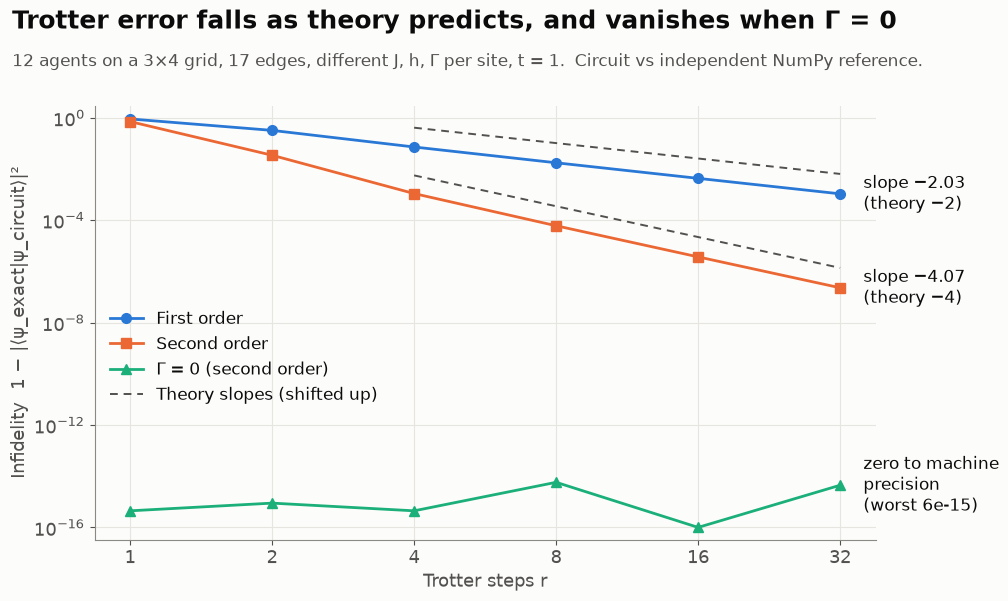

wrote C:\Users\Shiven\Desktop\hackathons\Qiskit-Fall-QuantumLarpers\validation\figures\fig1_trotter.png
slopes -2.026 -4.073  worst Gamma=0 6.22e-15


In [7]:
FLOOR = 1e-16   # log axes cannot show 0 or the tiny negatives rounding produces


def infidelities(system, order):
    H = compile_ising(system.n, system.edges, system.h, system.gamma)
    exact = exact_evolve(system, T_REF)
    return [
        float(infidelity(Statevector(evolve(H, T_REF, r, system.init_ones, order)).data, exact))
        for r in STEPS
    ]


def reference_line(ax, value_at_last, power, label=None):
    """Theory slope, drawn just above the data so the two can be compared by eye."""
    r = np.array([STEPS[2], STEPS[-1]], dtype=float)
    ax.plot(r, 6 * value_at_last * (r / r[-1]) ** power, color=INK_SECONDARY,
            linestyle=(0, (4, 3)), linewidth=1.4, zorder=1, label=label)


def fig1_trotter():
    system = standard_system()
    classical = standard_system(gamma_scale=0.0)
    first = infidelities(system, 1)
    second = infidelities(system, 2)
    zero = infidelities(classical, 2)
    zero_first = infidelities(classical, 1)

    slope_first = slope(STEPS, first, FIT_FROM)
    slope_second = slope(STEPS, second, FIT_FROM)
    worst_zero = max(abs(v) for v in zero + zero_first)

    assert abs(slope_first + 2) < 0.2, slope_first
    assert abs(slope_second + 4) < 0.3, slope_second
    assert worst_zero < 1e-12, worst_zero

    fig, ax = plt.subplots(figsize=(11, 6.2))
    fig.subplots_adjust(left=0.09, right=0.80, top=0.82, bottom=0.12)
    heading(fig, "Trotter error falls as theory predicts, and vanishes when Γ = 0",
            f"{system.n} agents on a 3×4 grid, {len(system.edges)} edges, different J, h, Γ per site, t = {T_REF:g}."
            "  Circuit vs independent NumPy reference.")

    ax.plot(STEPS, first, "-o", color=BLUE, label="First order")
    ax.plot(STEPS, second, "-s", color=ORANGE, label="Second order")
    shown_zero = np.maximum(np.abs(zero), FLOOR)
    ax.plot(STEPS, shown_zero, "-^", color=AQUA, label="Γ = 0 (second order)")
    reference_line(ax, first[-1], -2, "Theory slopes (shifted up)")
    reference_line(ax, second[-1], -4)

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_ylim(FLOOR / 3, 3)
    ax.set_xticks(STEPS, [str(r) for r in STEPS])
    ax.set_yticks([10.0 ** p for p in range(-16, 1, 4)])
    ax.set_xlabel("Trotter steps r")
    ax.set_ylabel("Infidelity  1 − |⟨ψ_exact|ψ_circuit⟩|²")
    ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.42))

    edge = STEPS[-1] * 1.12
    ax.annotate(f"slope −{abs(slope_first):.2f}\n(theory −2)", (edge, first[-1]), va="center",
                annotation_clip=False, fontsize=12.5)
    ax.annotate(f"slope −{abs(slope_second):.2f}\n(theory −4)", (edge, second[-1]), va="center",
                annotation_clip=False, fontsize=12.5)
    ax.annotate(f"zero to machine\nprecision\n(worst {worst_zero:.0e})", (edge, shown_zero[-1]),
                va="center", annotation_clip=False, fontsize=12.5)

    save(fig, "fig1_trotter", {
        "steps": list(STEPS),
        "infidelity_first_order": first,
        "infidelity_second_order": second,
        "infidelity_gamma_zero_first_order": zero_first,
        "infidelity_gamma_zero_second_order": zero,
        "slope_first_order": slope_first,
        "slope_second_order": slope_second,
        "fit_uses_steps_from": FIT_FROM,
        "worst_abs_gamma_zero_infidelity": worst_zero,
    })
    print(f"slopes {slope_first:.3f} {slope_second:.3f}  worst Gamma=0 {worst_zero:.2e}")


fig1_trotter()

## Fig 2: the memory wall

The deck's "why quantum" picture. Gate counts come from real compiled circuits, not a formula.
Memory is checked against an actual state vector before being extrapolated. This covers exact
state-vector simulation only, not every classical method.

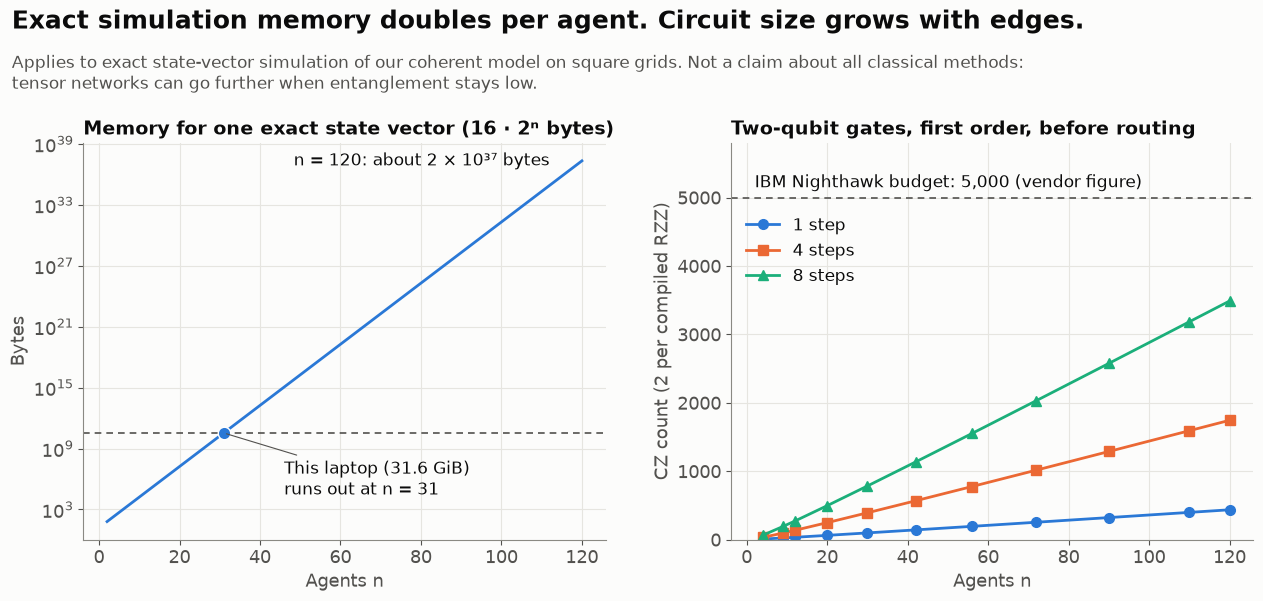

wrote C:\Users\Shiven\Desktop\hackathons\Qiskit-Fall-QuantumLarpers\validation\figures\fig2_memory_wall.png
wall n=31; n=120: 218 RZZ/step, 436 CZ/step, 11 steps fit the budget


In [8]:
GIB = 2 ** 30
LAPTOP_GIB = 31.6              # this machine's physical RAM
NIGHTHAWK_GATES = 5000         # IBM-stated two-qubit gate budget (vendor figure)
CZ_PER_RZZ = 2                 # Nighthawk is CZ-native, and an RZZ costs 2 CZ
GRIDS = [(2, 2), (3, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9), (9, 10), (10, 11), (10, 12)]
STEP_COUNTS = (1, 4, 8)


def statevector_bytes(n):
    return 16 * 2.0 ** n


def rzz_per_step(rows, cols):
    """Two-qubit gates in one first-order step, counted from the compiled circuit."""
    n = rows * cols
    edges = {pair: 1.0 for pair in grid_edges(rows, cols)}
    H = compile_ising(n, edges, [0.1] * n, [0.5] * n)
    circuit = evolve(H, 1.0, 1, order=1)
    count = circuit.count_ops().get("rzz", 0)
    assert count == len(edges), (count, len(edges))
    return count


def fig2_memory_wall():
    for n in (10, 14):
        measured = Statevector.from_int(0, 2 ** n).data.nbytes
        assert measured == statevector_bytes(n), (n, measured)

    sizes = [r * c for r, c in GRIDS]
    rzz = [rzz_per_step(r, c) for r, c in GRIDS]
    cz = np.array(rzz) * CZ_PER_RZZ

    ns = np.arange(2, sizes[-1] + 1)
    wall = int(ns[statevector_bytes(ns) > LAPTOP_GIB * GIB][0])
    assert wall == 31, wall

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True)
    fig.subplots_adjust(left=0.07, right=0.97, top=0.76, bottom=0.12, wspace=0.24)
    heading(fig, "Exact simulation memory doubles per agent. Circuit size grows with edges.",
            "Applies to exact state-vector simulation of our coherent model on square grids. "
            "Not a claim about all classical methods:\n"
            "tensor networks can go further when entanglement stays low.")

    left.plot(ns, statevector_bytes(ns), color=BLUE)
    left.axhline(LAPTOP_GIB * GIB, color=INK_SECONDARY, linestyle=(0, (4, 3)), linewidth=1.2)
    left.plot([wall], [statevector_bytes(wall)], "o", color=BLUE, markeredgecolor="white", markersize=9)
    left.set_yscale("log")
    left.set_yticks([10.0 ** p for p in range(3, 40, 6)])
    left.set_ylabel("Bytes")
    left.set_title("Memory for one exact state vector (16 · 2ⁿ bytes)")
    left.set_xlabel("Agents n")
    left.annotate(f"This laptop ({LAPTOP_GIB:g} GiB)\nruns out at n = {wall}",
                  (wall, LAPTOP_GIB * GIB), xytext=(46, 3e4), fontsize=12.5,
                  arrowprops={"arrowstyle": "-", "color": INK_SECONDARY, "linewidth": 0.8})
    left.text(sizes[-1] - 8, statevector_bytes(sizes[-1]),
              f"n = {sizes[-1]}: about 2 × 10³⁷ bytes", ha="right", va="center", fontsize=12.5)

    for steps, color, marker in zip(STEP_COUNTS, (BLUE, ORANGE, AQUA), "os^"):
        label = f"{steps} step" + ("" if steps == 1 else "s")
        right.plot(sizes, cz * steps, "-" + marker, color=color, label=label)
    right.axhline(NIGHTHAWK_GATES, color=INK_SECONDARY, linestyle=(0, (4, 3)), linewidth=1.2)
    right.text(2, NIGHTHAWK_GATES + 90, "IBM Nighthawk budget: 5,000 (vendor figure)", va="bottom", fontsize=12.5)
    right.set_ylim(0, 5800)
    right.set_title("Two-qubit gates, first order, before routing")
    right.set_xlabel("Agents n")
    right.set_ylabel("CZ count (2 per compiled RZZ)")
    right.legend(loc="upper left", bbox_to_anchor=(0.0, 0.85))

    save(fig, "fig2_memory_wall", {
        "grid_shapes": GRIDS,
        "agents": sizes,
        "rzz_per_first_order_step_measured": rzz,
        "cz_per_first_order_step": cz.tolist(),
        "laptop_gib": LAPTOP_GIB,
        "first_n_exceeding_laptop": wall,
        "bytes_at_largest_n": statevector_bytes(sizes[-1]),
        "max_first_order_steps_in_nighthawk_budget_at_largest_n": int(NIGHTHAWK_GATES // cz[-1]),
    })
    print(f"wall n={wall}; n={sizes[-1]}: {rzz[-1]} RZZ/step, {cz[-1]} CZ/step, "
          f"{NIGHTHAWK_GATES // cz[-1]} steps fit the budget")


fig2_memory_wall()

## Fig 5: error in the numbers the app reports

Uses the worst error across several times, because a single time can land on an accidental zero
crossing. First and second order overlap exactly on Z-basis numbers: they differ only by diagonal
phases, which can't change Z-basis probabilities from a basis-state start. ⟨X⟩ is off-diagonal,
so it shows they really are different circuits.

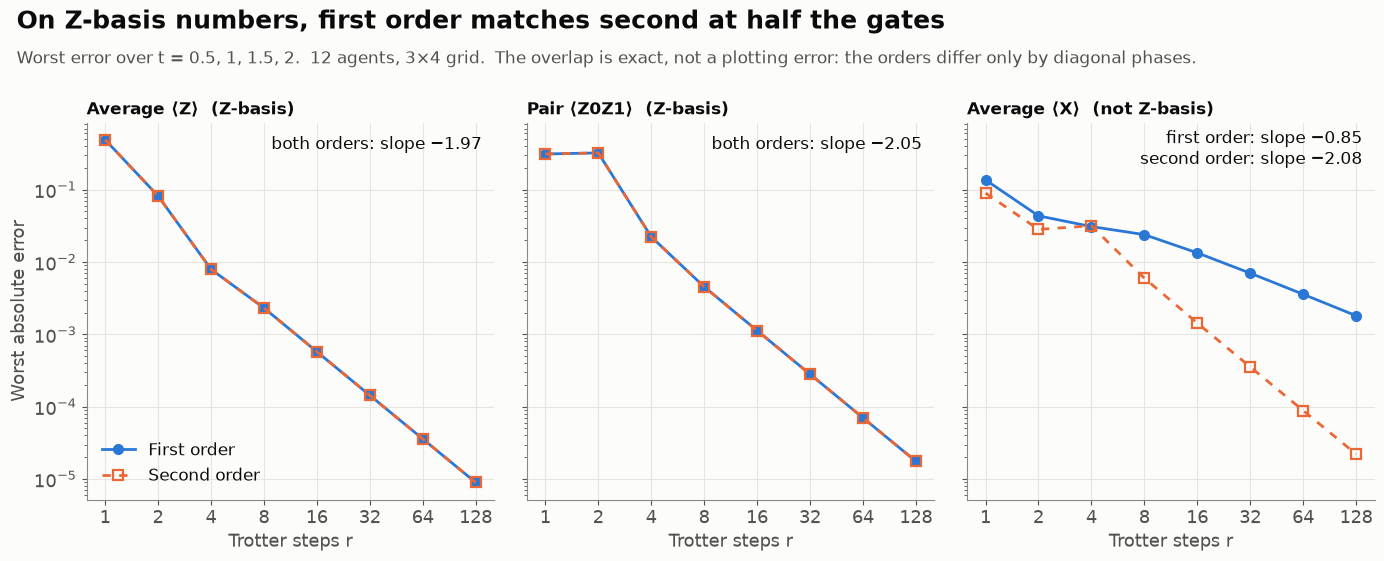

wrote C:\Users\Shiven\Desktop\hackathons\Qiskit-Fall-QuantumLarpers\validation\figures\fig5_observable_error.png
M r=16 err 5.75e-04 slopes {'first': -1.97, 'second': -1.97} first ['4.9e-01', '8.2e-02', '7.9e-03', '2.3e-03', '5.8e-04', '1.4e-04', '3.6e-05', '9.0e-06'] second ['4.9e-01', '8.2e-02', '7.9e-03', '2.3e-03', '5.8e-04', '1.4e-04', '3.6e-05', '9.0e-06']
ZZ r=16 err 1.13e-03 slopes {'first': -2.05, 'second': -2.05} first ['3.1e-01', '3.2e-01', '2.2e-02', '4.6e-03', '1.1e-03', '2.8e-04', '7.0e-05', '1.8e-05'] second ['3.1e-01', '3.2e-01', '2.2e-02', '4.6e-03', '1.1e-03', '2.8e-04', '7.0e-05', '1.8e-05']
X r=16 err 1.34e-02 slopes {'first': -0.85, 'second': -2.08} first ['1.4e-01', '4.3e-02', '3.1e-02', '2.4e-02', '1.3e-02', '7.0e-03', '3.6e-03', '1.8e-03'] second ['9.0e-02', '2.8e-02', '3.2e-02', '6.0e-03', '1.4e-03', '3.6e-04', '8.9e-05', '2.2e-05']


In [9]:
TIMES = (0.5, 1.0, 1.5, 2.0)
OBS_STEPS = (1, 2, 4, 8, 16, 32, 64, 128)
PAIR = (0, 1)   # a coupled pair that includes a seeded agent


def observables(psi, n):
    return {
        "M": magnetization(psi, n),
        "ZZ": zz_expectation(psi, n, *PAIR),
        "X": x_bar(psi, n),
    }


def worst_errors(system, H, exact, order):
    """{observable: [worst error over TIMES, one per step count]}."""
    errors = {name: [] for name in ("M", "ZZ", "X")}
    for r in OBS_STEPS:
        worst = dict.fromkeys(errors, 0.0)
        for t in TIMES:
            psi = Statevector(evolve(H, t, r, system.init_ones, order)).data
            got = observables(psi, system.n)
            for name in errors:
                worst[name] = max(worst[name], abs(got[name] - exact[t][name]))
        for name in errors:
            errors[name].append(worst[name])
    return errors


def fig5_observable_error():
    system = standard_system()
    H = compile_ising(system.n, system.edges, system.h, system.gamma)
    exact = {t: observables(exact_evolve(system, t), system.n) for t in TIMES}
    first = worst_errors(system, H, exact, 1)
    second = worst_errors(system, H, exact, 2)

    for name in ("M", "ZZ"):
        gap = max(abs(a - b) for a, b in zip(first[name], second[name]))
        assert gap < 1e-11, (name, gap)
        assert abs(slope(OBS_STEPS, first[name], FIT_FROM) + 2) < 0.2, name

    slopes = {
        name: {"first": slope(OBS_STEPS, first[name], FIT_FROM),
               "second": slope(OBS_STEPS, second[name], FIT_FROM)}
        for name in first
    }

    panels = (("M", "Average ⟨Z⟩  (Z-basis)"),
              ("ZZ", f"Pair ⟨Z{PAIR[0]}Z{PAIR[1]}⟩  (Z-basis)"),
              ("X", "Average ⟨X⟩  (not Z-basis)"))
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.8), sharey=True, sharex=True)
    fig.subplots_adjust(left=0.065, right=0.985, top=0.78, bottom=0.13, wspace=0.08)
    heading(fig, "On Z-basis numbers, first order matches second at half the gates",
            f"Worst error over t = {', '.join(f'{t:g}' for t in TIMES)}.  12 agents, 3×4 grid.  "
            "The overlap is exact, not a plotting error: the orders differ only by diagonal phases.")

    for ax, (name, title) in zip(axes, panels):
        ax.plot(OBS_STEPS, first[name], "-o", color=BLUE, label="First order")
        ax.plot(OBS_STEPS, second[name], linestyle=(0, (3, 3)), marker="s", markerfacecolor="none",
                markeredgewidth=1.6, color=ORANGE, label="Second order")
        ax.set_xscale("log", base=2)
        ax.set_yscale("log")
        ax.set_xticks(OBS_STEPS, [str(r) for r in OBS_STEPS])
        ax.set_title(title, fontsize=12.5)
        ax.set_xlabel("Trotter steps r")
    axes[0].set_ylabel("Worst absolute error")
    axes[0].legend(loc="lower left")
    for ax, name in zip(axes, ("M", "ZZ")):
        ax.text(0.97, 0.93, f"both orders: slope −{abs(slopes[name]['first']):.2f}",
                transform=ax.transAxes, ha="right", fontsize=12.5)
    axes[2].text(0.97, 0.93, f"first order: slope −{abs(slopes['X']['first']):.2f}\n"
                             f"second order: slope −{abs(slopes['X']['second']):.2f}",
                 transform=axes[2].transAxes, ha="right", va="center", fontsize=12.5)

    save(fig, "fig5_observable_error", {
        "times": list(TIMES),
        "steps": list(OBS_STEPS),
        "worst_error_first_order": first,
        "worst_error_second_order": second,
        "slopes_from_r4": slopes,
    })
    for name in first:
        print(name, "r=16 err", f"{first[name][4]:.2e}", "slopes", {k: round(v, 2) for k, v in slopes[name].items()},
              "first", [f"{v:.1e}" for v in first[name]], "second", [f"{v:.1e}" for v in second[name]])


fig5_observable_error()

## Fig 4: Glauber vs coherent

Shared: J, h, graph, seeded agents. Glauber adds a temperature, the coherent model adds Γ, and
their clocks are different units, so each gets its own time axis.

The core difference is energy. Unitary evolution conserves ⟨H⟩ and has no bath to absorb energy,
and here the seeded agent stays near where it started. Glauber is coupled to a heat bath, so it
forgets the start and settles at a temperature-set equilibrium.

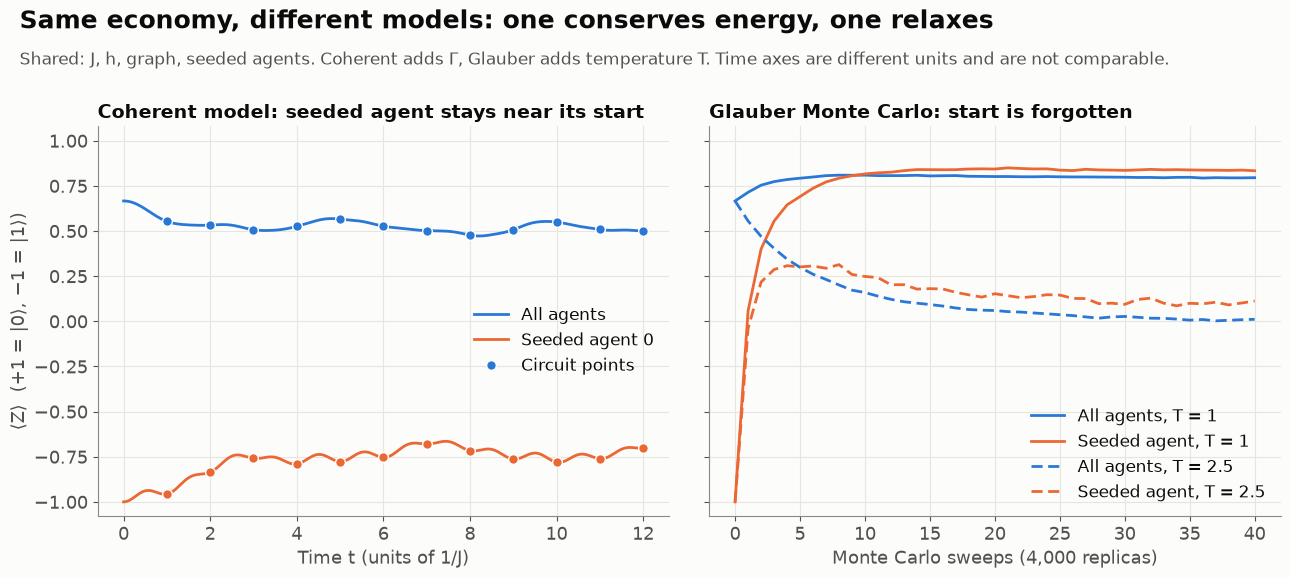

wrote C:\Users\Shiven\Desktop\hackathons\Qiskit-Fall-QuantumLarpers\validation\figures\fig4_glauber.png
{'max_abs_gap_circuit_vs_exact': 0.0015676567550906295, 'coherent_energy_start': -3.9702289932583006, 'coherent_energy_max_drift': 2.886579864025407e-14, 'coherent_seeded_agent_z_final': -0.7023128002565563, 'coherent_seeded_agent_z_max': -0.6644966369794397, 'coherent_average_z_range': [0.47255594446606725, 0.6666666666666666], 'glauber': {'1.0': {'final_average': 0.7955, 'final_seeded_agent': 0.834}, '2.5': {'final_average': 0.011333333333333334, 'final_seeded_agent': 0.1125}}}


In [10]:
GLAUBER_T_MAX = 12.0
SWEEPS = 40
TEMPERATURES = (1.0, 2.5)
SEEDED_AGENT = 0
MAX_DT = 0.05


def fig4_glauber():
    system = standard_system()
    n = system.n
    H = compile_ising(n, system.edges, system.h, system.gamma)
    H_matrix = hamiltonian(n, system.edges, system.h, system.gamma)

    times = np.linspace(0, GLAUBER_T_MAX, 241)
    states = exact_series(system, times)
    z = np.array([z_expectations(psi, n) for psi in states])
    coherent_M, coherent_agent = z.mean(axis=1), z[:, SEEDED_AGENT]
    energy = np.array([np.real(np.vdot(psi, H_matrix @ psi)) for psi in states])
    energy_drift = float(np.abs(energy - energy[0]).max())
    assert energy_drift < 1e-9, energy_drift

    check_times = np.arange(1.0, GLAUBER_T_MAX + 0.5, 1.0)
    circuit_z = []
    for t in check_times:
        psi = Statevector(evolve(H, t, math.ceil(t / MAX_DT), system.init_ones, 2)).data
        circuit_z.append(z_expectations(psi, n))
    circuit_z = np.array(circuit_z)
    circuit_gap = float(np.abs(
        circuit_z - np.array([z_expectations(p, n) for p in exact_series(system, check_times)])
    ).max())
    assert circuit_gap < 2e-2, circuit_gap

    runs = {T: run_glauber(system, T, SWEEPS) for T in TEMPERATURES}
    sweeps = np.arange(SWEEPS + 1)

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
    fig.subplots_adjust(left=0.075, right=0.985, top=0.78, bottom=0.13, wspace=0.07)
    heading(fig, "Same economy, different models: one conserves energy, one relaxes",
            "Shared: J, h, graph, seeded agents. Coherent adds Γ, Glauber adds temperature T. "
            "Time axes are different units and are not comparable.")

    left.plot(times, coherent_M, color=BLUE, label="All agents")
    left.plot(times, coherent_agent, color=ORANGE, label=f"Seeded agent {SEEDED_AGENT}")
    left.plot(check_times, circuit_z.mean(axis=1), "o", color=BLUE, markeredgecolor="white", label="Circuit points")
    left.plot(check_times, circuit_z[:, SEEDED_AGENT], "o", color=ORANGE, markeredgecolor="white")
    left.set_title("Coherent model: seeded agent stays near its start")
    left.set_xlabel("Time t (units of 1/J)")
    left.set_ylabel("⟨Z⟩  (+1 = |0⟩, −1 = |1⟩)")
    left.set_ylim(-1.08, 1.08)
    left.legend(loc="center right", bbox_to_anchor=(1.0, 0.45))

    for T, style in zip(TEMPERATURES, ("-", (0, (4, 2)))):
        right.plot(sweeps, runs[T].mean(axis=1), color=BLUE, linestyle=style, label=f"All agents, T = {T:g}")
        right.plot(sweeps, runs[T][:, SEEDED_AGENT], color=ORANGE, linestyle=style, label=f"Seeded agent, T = {T:g}")
    right.set_title("Glauber Monte Carlo: start is forgotten")
    right.set_xlabel("Monte Carlo sweeps (4,000 replicas)")
    right.legend(loc="lower right")

    data = {
        "max_abs_gap_circuit_vs_exact": circuit_gap,
        "coherent_energy_start": float(energy[0]),
        "coherent_energy_max_drift": energy_drift,
        "coherent_seeded_agent_z_final": float(coherent_agent[-1]),
        "coherent_seeded_agent_z_max": float(coherent_agent.max()),
        "coherent_average_z_range": [float(coherent_M.min()), float(coherent_M.max())],
        "glauber": {
            str(T): {
                "final_average": float(runs[T][-1].mean()),
                "final_seeded_agent": float(runs[T][-1][SEEDED_AGENT]),
            }
            for T in TEMPERATURES
        },
    }
    save(fig, "fig4_glauber", data)
    print(data)


fig4_glauber()

## Fig 3: entanglement entropy

With no transverse field, there is no entanglement. That is only true because we start from a
definite bit-string: ZZ terms alone can entangle a superposition. Here entanglement is a
correlation diagnostic of the model, not a claim about real people.

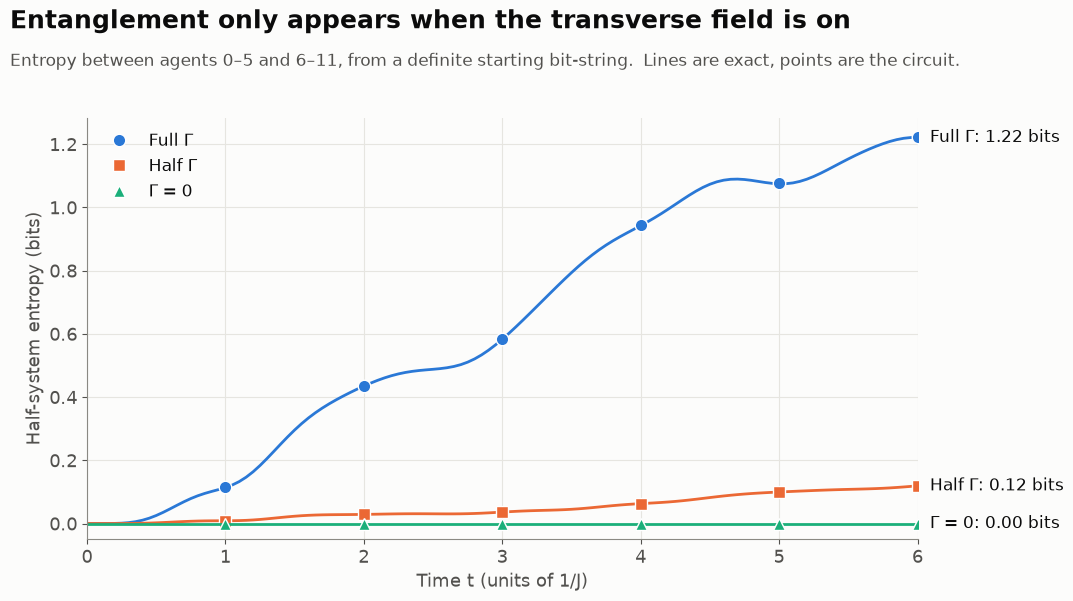

wrote C:\Users\Shiven\Desktop\hackathons\Qiskit-Fall-QuantumLarpers\validation\figures\fig3_entropy.png
gamma scale 1: S(t=6) = 1.221 bits, circuit gap 1.5e-03
gamma scale 0.5: S(t=6) = 0.119 bits, circuit gap 1.8e-04
gamma scale 0: S(t=6) = 0.000 bits, circuit gap 0.0e+00


In [11]:
ENTROPY_T_MAX = 6.0
MAX_DT = 0.05
SCALES = ((1.0, "Full Γ", BLUE, "o"), (0.5, "Half Γ", ORANGE, "s"), (0.0, "Γ = 0", AQUA, "^"))


def fig3_entropy():
    times = np.linspace(0, ENTROPY_T_MAX, 121)
    check_times = np.arange(1.0, ENTROPY_T_MAX + 0.5, 1.0)

    fig, ax = plt.subplots(figsize=(11, 6.2))
    fig.subplots_adjust(left=0.085, right=0.84, top=0.8, bottom=0.12)
    heading(fig, "Entanglement only appears when the transverse field is on",
            "Entropy between agents 0–5 and 6–11, from a definite starting bit-string.  "
            "Lines are exact, points are the circuit.")

    data = {"times": times.tolist(), "circuit_times": check_times.tolist(), "curves": {}}
    for scale, label, color, marker in SCALES:
        system = standard_system(gamma_scale=scale)
        n = system.n
        H = compile_ising(n, system.edges, system.h, system.gamma)
        exact = [half_entropy(psi, n) for psi in exact_series(system, times)]
        circuit = [
            half_entropy(
                Statevector(evolve(H, t, math.ceil(t / MAX_DT), system.init_ones, 2)).data, n)
            for t in check_times
        ]
        gap = max(abs(c - exact[int(np.argmin(np.abs(times - t)))]) for c, t in zip(circuit, check_times))
        assert gap < 2e-2, (label, gap)
        ax.plot(times, exact, color=color)
        ax.plot(check_times, circuit, marker, color=color, markeredgecolor="white", markersize=9, label=label)
        ax.annotate(f"{label}: {exact[-1]:.2f} bits", (ENTROPY_T_MAX * 1.015, exact[-1]), va="center",
                    annotation_clip=False, fontsize=12.5)
        data["curves"][label] = {"gamma_scale": scale, "exact": exact, "circuit": circuit,
                                 "max_gap_circuit_vs_exact": gap}

    zero = data["curves"]["Γ = 0"]
    assert max(zero["exact"] + zero["circuit"]) < 1e-9
    assert data["curves"]["Full Γ"]["exact"][-1] > 0.5

    ax.set_xlabel("Time t (units of 1/J)")
    ax.set_ylabel("Half-system entropy (bits)")
    ax.set_xlim(0, ENTROPY_T_MAX)
    ax.set_ylim(bottom=-0.05)
    ax.legend(loc="upper left")

    save(fig, "fig3_entropy", data)
    for curve in data["curves"].values():   # ASCII only: Windows consoles can't print Gamma
        print(f"gamma scale {curve['gamma_scale']:g}: S(t={ENTROPY_T_MAX:g}) = {curve['exact'][-1]:.3f} bits, "
              f"circuit gap {curve['max_gap_circuit_vs_exact']:.1e}")


fig3_entropy()